In [1]:
%load_ext autoreload
%autoreload 2

## Dual-Channel Calibration（双通道配准）

核心目标：求出**红（受体）通道坐标 → 绿（供体）通道坐标**的映射，供后续 FRET/共定位使用。

**约定**：两通道各用**自己窗口的本地坐标**（右通道局部 x 从 0 起算）。两通道各自从半幅起点裁切，所以两个 local 坐标本来就重合 —— 256 px 的大平移在裁切那一刻就被吸收了。实测配对位移中位数只有约 1.5 px，`red → green` 的映射接近恒等。

**分工原则**（重要）：
- **图像**只做漂移校正（全局平移，光度中性）；
- **坐标**才做完整标定（2D 多项式/仿射）。
  理由：对图像做空间变化的形变重采样会让 PSF 插值核随位置变化，从而引入逐分子的 κ 抖动，这种抖动无法被一个全局 γ 吸收，会直接 broaden FRET 分布。

**流程**：切通道 → 各自 detect+localize → 一对一配对 → 交叉验证选阶 → 拟合 → 可视化 → 一站式落盘。
所有实现都在 `smlm/multiplex/`，本节的 cell 只做调用与检查。


In [2]:
# ============ 双通道取框 (只填绿通道; 红 = 绿 + split_x) ============
import numpy as np
import matplotlib.pyplot as plt
import smlm.multiplex as mp
from smlm.camera import EMCCD
from smlm.io import load_raw

plt.rcParams['font.sans-serif'] = ['Microsoft YaHei', 'SimHei', 'DejaVu Sans']
plt.rcParams['axes.unicode_minus'] = False

CALIB_FILES = [r"G:\PacBio\近观DNA_FRET\20261109\std2.sif",
               r"G:\PacBio\近观DNA_FRET\20261109\std.sif"]
CALIB_PATH  = r"G:\PacBio\近观DNA_FRET\20261109\dualcal_v2.npz"   # 别用 <源文件>_dualcal.npz, 会覆盖历史标定
SPLIT_X     = 256      # 双视角分界列
ROWS        = (0, 512)


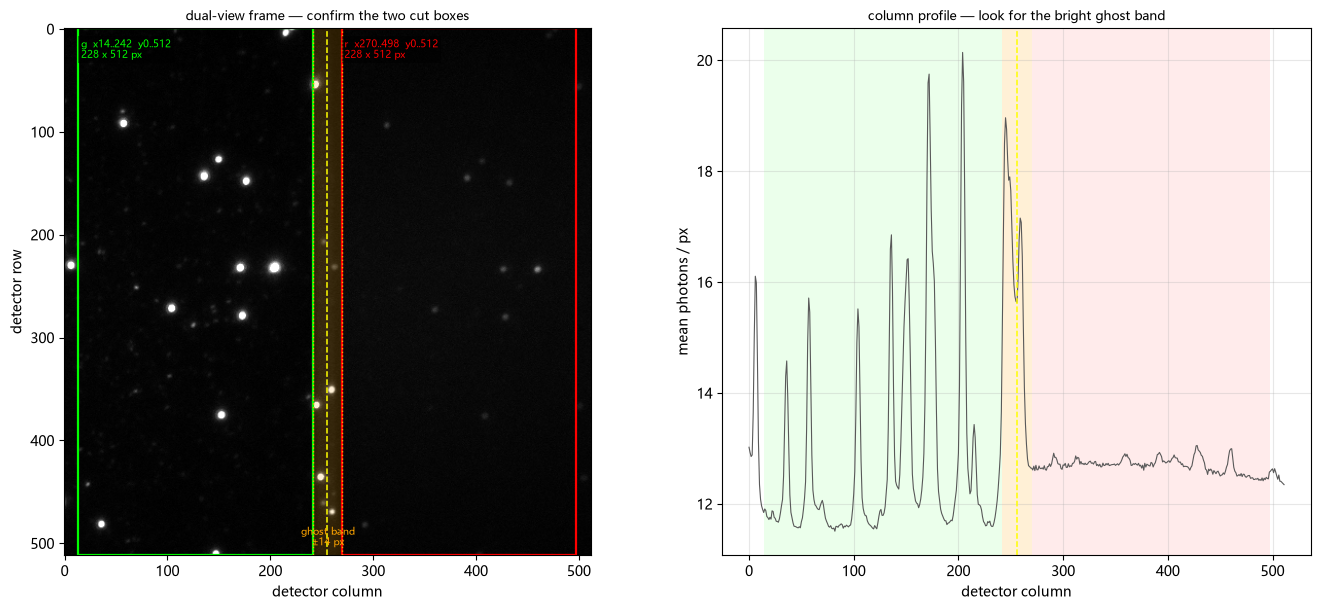

  g: detector y0..512 x14..242 (512x228)
  r: detector y0..512 x270..498 (512x228)
绿框 (14, 242)   红框 (270, 498)


In [ ]:
# Check the first File
stack = EMCCD(conv_factor=5.75, em_gain=300).process(load_raw(CALIB_FILES[0]), pixel_size=96.7)
REF_CROP = dict(y=(0, 512), x=(14, 242)) # reference channel FOV
CROPS = mp.crops_from_ref(REF_CROP, SPLIT_X, reference='g', moving='r') # ()

mp.plot_cut_windows(stack, CROPS, split_x=SPLIT_X, seam_hint=mp.SEAM_HINT)
plt.show()

stack_g, stack_r, WINDOWS = mp.split_from_crops(stack, CROPS, verbose=True)
ROI = mp.DualViewROI(split_x=SPLIT_X, row_range=ROWS, n_cols=stack.shape[2])

_lo, _hi = SPLIT_X - mp.SEAM_HINT, SPLIT_X + mp.SEAM_HINT
if CROPS['g']['x'][1] > _lo or CROPS['r']['x'][0] < _hi:
    print(f'⚠️ 切进鬼影带 ({_lo}~{_hi}): 绿右界 {CROPS["g"]["x"][1]}, '
          f'红左界 {CROPS["r"]["x"][0]}')
print(f'绿框 {CROPS["g"]["x"]}   红框 {CROPS["r"]["x"]}')

### 模块分工

配准的全部实现都在 `smlm/multiplex/`，notebook 里只保留"人工取框"这一步：

| 文件 | 职责 |
|---|---|
| `transform.py` | `DualViewCalibration`：映射、`jacobian_at`、`save/load` |
| `pair.py` | `PairSet`、`pair_channels`（由粗到细）、`merge_pairs`（分文件配额） |
| `fit.py` | `fit_transform`（4·MAD 稳健）、**`cv_select_order`**、`residual_report` |
| `channels.py` | `DualViewROI`、`crops_from_ref`、`split_from_crops`、`seam_windows` |
| `coords.py` | `DualViewGeometry`：分析窗口 ↔ 标定窗口 ↔ 参考通道 |
| `pipeline.py` | `calibrate_dual_view`、`calib_one_file`、`load_multi`、`localize_channel` |
| `viz.py` | `plot_cut_windows`（取框确认图）、位移场 / 残差 / 通道叠加 |

下一格是**一站式批量标定**：对 `CALIB_FILES` 里每个文件各跑一遍
「按 `CROPS` 切通道 → 平均图定位 → 一对一配对」，然后合并（按文件配额）→
交叉验证选阶 → 稳健拟合 → 落盘，最后给逐文件汇总表和残差对照。


In [ ]:
# ============ 批量标定: 每文件 裁切+定位+配对 -> 合并 -> 选阶拟合 ============
import numpy as np
import matplotlib.pyplot as plt
import smlm.multiplex as mp

# 每个文件独立配对(跨文件配没意义), 合并前会检查各文件 shift 是否一致
calib, crep = mp.calibrate_dual_view(
    CALIB_FILES, roi=ROI, crops=CROPS,
    order='auto', cap_per_file=2000, min_consistent_shift=1.0,
    save_path=CALIB_PATH, verbose=False)

print(f"{'file':>10} {'pairs':>6} {'shift_x':>8} {'shift_y':>8} {'resid':>7}")
for name, s in crep['per_file'].items():
    sh = s['shift_xy'] or [np.nan, np.nan]
    print(f'{name:>10} {s["n_pairs"]:>6} {sh[0]:>+8.2f} {sh[1]:>+8.2f} '
          f'{s["resid_median"]:>7.2f}')
print(f'合并 {crep["n_pairs"]} pairs / {crep["n_files"]} 文件   '
      f'shift 极差 {tuple(crep["shift_spread"])} px   '
      f'{"一致" if crep["shift_consistent"] else "⚠️ 不一致"}')
print('CV (cv_p84 px): ' + '   '.join(
    f'o{t["order"]}:{t["cv_p84_px"]:.3f}' for t in calib.metrics['cv']))
print(f'-> order {calib.poly_order}   残差 med {calib.metrics["poly"]["median"]:.3f}'
      f' / p84 {calib.metrics["poly"]["p84"]:.3f} px')
print('saved ->', CALIB_PATH)

mp.plot_overview(calib, crep['pairs'])
plt.show()


## Dual Channel Loading

In [ ]:
# ============ 数据 + 配准参数 (同一个目录) ============
import os
import numpy as np
import smlm.multiplex as mp

src = r"G:\PacBio\近观DNA_FRET\20261109\sample1_532nm_2mW_0p1S_2000frames_fov6.sif"
CALIB_PATH = os.path.join(os.path.dirname(src), 'dualcal_v2.npz')   # 同目录下的标定

calib = mp.DualViewCalibration.load(CALIB_PATH)
print('data  ->', src)
print('calib ->', CALIB_PATH)
calib.report()


In [ ]:
# read sif
from smlm.camera import EMCCD
from smlm.imgprocess import Pipeline, Crop, SelectFrames
from smlm.viz import show_frames
raw = load_raw(src)
print(raw.data.shape, raw.n_frames, raw.em_gain, raw.exposure_time)
pixel_size=96 # nm/pixel
cam = EMCCD(conv_factor=5.75, em_gain=300)
image = cam.process(raw, pixel_size=106.6)
prep = Pipeline(Crop(y=(0,512), x=(0, 512)),
                SelectFrames(stop=None))
stack = prep(image)
print(stack.shape)


In [ ]:
# 保存图像为 tif(与源文件同目录同名, 加 _photons 后缀)
import os
from smlm.io import save_tif
dst = os.path.splitext(src)[0] + "_raw.tif"
save_tif(raw.data, dst)

In [ ]:
# ============ 分析取框 = 标定取框 + 上下留白 (红 = 绿 + split_x) ============
# mp.analysis_crops 直接复用 calib.roi 里存的手写取框; 红通道由"绿 + split_x"派生。
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

import smlm.multiplex as mp
from smlm.viz import show_frames

# trim 只能是**向内收**: 取框 = (y0+yt, y1-yt) x (x0+xt, x1-xt)。
# 给负数会向外扩。真正常看的边界是**标定点云的实际覆盖**, order>=2 时超出就是
# 外推, geom 会警告; order=1 是仿射, 外推精确, 只有提示。
X_TRIM = 0      # 两侧对称收缩, 对齐关系不变
Y_TRIM = 50     # 漂移余量(实测漂移 5.7 px); 漂移超出由 check_drift_margin 报出

CROPS = dict(zip(('g', 'r'), mp.analysis_crops(calib, x_trim=X_TRIM, y_trim=Y_TRIM)))

# 多通道容器: 像素 + 各通道窗口偏移 + 配准, 一次给全。
# reg 里放"该通道 -> 参考通道"的标定, 参考通道(绿)不写。
multi = mp.multi_from_crops(stack, CROPS, reference='g', reg={'r': calib},
                            margin=Y_TRIM, roi_dict=calib.roi)
print(multi)
stack_g, stack_r = multi.channel('g'), multi.channel('r')   # 视图, 不拷贝

geom = multi.geometry()        # 窗口/偏移/配准都在 multi 里, 不用再手传
geom.report()
print('calib offset:', {ch: geom.calib_delta(ch) for ch in geom.windows})

# 两通道公共可用区: 画在图上确认没有裁到视场外
VALID_BOX = geom.valid_box()
ax = show_frames(stack, title=f'分析取框  X_TRIM={X_TRIM}, Y_TRIM={Y_TRIM} px')
for ch, col in (('g', 'lime'), ('r', 'red')):
    c = CROPS[ch]
    y0_, y1_ = c['y']
    x0_, x1_ = c['x']
    ax.add_patch(Rectangle((x0_ - 0.5, y0_ - 0.5), x1_ - x0_, y1_ - y0_,
                           fill=False, ec=col, lw=1.4, label=f'{ch} crop'))
vb = VALID_BOX
ax.add_patch(Rectangle((CROPS['g']['x'][0] + vb['x'][0] - 0.5,
                        CROPS['g']['y'][0] + vb['y'][0] - 0.5),
                       vb['x'][1] - vb['x'][0], vb['y'][1] - vb['y'][0],
                       fill=False, ec='yellow', ls='--', lw=1.0,
                       label='common valid'))
ax.legend(fontsize=8, loc='upper right')
plt.show()


## Detect + Localize + Drift Correction

1. **Detect + Localize**：两通道分别用 `LocalMaxDetector` + `MLELocalizer`，按通道缓存成
   `<src>_green.locs.npz` / `<src>_red.locs.npz`（同样的输入+参数再跑直接读盘）。

2. **漂移估计（Phase 3）**：`CloudDriftEstimator` 估**一条**物理漂移，顺序是
   **先配准、再合并点云**：

   ```
   各通道定位 --(配准, 坐标层)--> 绿坐标系 --(合并)--> 一条点云 --> 一条漂移
   ```

   漂移是样品相对探测器的运动，两个通道看到的是同一个物理位移，只是各自成像在不同像素
   坐标里（像元尺度差 ~0.1%）。合并后点密度翻倍，估计更稳，也顺便解决红通道分子少、
   单独估不稳的问题。
   ⚠️ **绝不能**各自估一条再合并 —— 那会把"通道间固定的 ~1.4 px 错位"和真实的逐帧
   漂移混在一起，得到两条互不一致的轨迹。

3. **换算回各通道**：合并点云给出的 `d_ref` 是绿像素位移；红通道看到的是 `J⁻¹·d_ref`
   （`J = d(ref)/d(red)`，取视场中心）。双视角的形变只有 ~0.1 px，用中心 J 的误差在
   1e-3 相对量，可忽略。

4. **漂移校正**：`DriftCorrector` 做亚像素傅里叶平移（光度中性，不改 PSF 形状），
   同时平移图像与定位。裁切窗口按「实际最大漂移 + 缓冲」自动算；窗口原点的移动并入
   `DualViewGeometry`，所以 `CORR_OFF_*` 直接从几何对象读，不用手写。

**分工**：图像只做平移；空间变化的形变一律留给坐标层的配准。


In [ ]:
# ============ Detect + Localize: 两通道各跑一遍(按通道缓存) ============
# detect -> localize -> filter -> 缓存 这一整套就在 mp.localize_channel 里,
# 这里只负责给参数。缓存文件与源文件同目录: <src>_green.locs.npz / <src>_red.locs.npz
import os
import numpy as np
import matplotlib.pyplot as plt

import smlm.multiplex as mp
from smlm import viz

# 真实样品很暗(单帧峰值 ~30、背景 ~10), 阈值必须放宽:
#   k_sigma 越小 -> 检出越多; 反正后面还要按"至少亮 3 帧"筛, 假点留不下来。
K_SIGMA_SAMPLE = dict(green=2.0, red=1.4)

DET_KW = dict(edge=5, f_em=np.sqrt(2), bg_window=15, max_size=7, min_neighbors=2)
LOC_KW = dict(edge=5, F_EM=np.sqrt(2), use_pixel=False, use_gradient=True,
              n_jobs=14, verbose=False)
FILT_KW = dict(photons=(3, 1e7), bg=(0, 1e5), sigma=(0.7, 4.0), lp=None)  # 暗样品, 光子下限放低

# 注意是当前样品的 src, 不是标定图那份
_base = os.path.splitext(src)[0]
print('cache base ->', _base)

locs_g = mp.localize_channel(stack_g, k_sigma=K_SIGMA_SAMPLE['green'],
                             det_kw=DET_KW, loc_kw=LOC_KW, filt_kw=FILT_KW,
                             src_path=_base + '_green', verbose=True, tag='green')
locs_r = mp.localize_channel(stack_r, k_sigma=K_SIGMA_SAMPLE['red'],
                             det_kw=DET_KW, loc_kw=LOC_KW, filt_kw=FILT_KW,
                             src_path=_base + '_red', verbose=True, tag='red')

for tag, l in [('green', locs_g), ('red', locs_r)]:
    print(f'{tag}: {len(l)} locs = {len(l) / stack_g.n_frames:.2f}/frame  '
          f'photons med {np.median(l.photons):.0f}  '
          f'sigma med {np.median(l.sigma):.2f} px  '
          f'lp med {np.median(l.lp):.3f}')

# 快速看一眼单帧检出情况
for st, l, c, name in [(stack_g, locs_g, 'lime', 'green'),
                       (stack_r, locs_r, 'red', 'red')]:
    ax = viz.overlay_points(st, l, frames=0, color=c, marker='x',
                            size=30, linewidth=0.8)
    ax.set_title(f'{name} frame 0  ({int((l.frame == 0).sum())} locs)')
    plt.show()


In [ ]:
# ============ 漂移: 先配准点云 -> 估一条物理漂移 -> 按各通道尺度换算 ============
# 关键顺序: 通道间配准是**固定**的坐标映射, 先把各通道点搬到参考坐标系再合并,
# 才能估出"一条"物理漂移。各自估一条会把通道错位和真实漂移混在一起。
# 换算: 合并点云给出的 d_ref 是绿像素位移; 其他通道看到的是 J^-1 · d_ref
#       (J = d(ref)/d(ch), 取视场中心)。
import numpy as np
from dataclasses import replace
import smlm.multiplex as mp

FRAMES_PER_SEG = 10   # 别用大值: Stage1 以第 0 段为参考, 段内漂移恒为 0
PAD = 4               # 裁切缓冲
EXTRA_TRIM = 0        # 漂移校正后再往里收几 px(嫌边缘脏就调大)

LOCS = {'g': locs_g, 'r': locs_r}

# multi 里已经带着窗口偏移和各通道配准, 几何对象现造即可
md = mp.estimate_drift_multi(multi, LOCS, frames_per_seg=FRAMES_PER_SEG,
                             verbose=True)

# 所有通道用**同一个**裁切尺寸 -> 校正后同尺寸、同局部坐标原点
multi_c, locs_c, geom_c = mp.correct_multi(multi, LOCS, md,
                                           pad=PAD, extra_trim=EXTRA_TRIM)

corr_g, corr_r = multi_c.channel('g'), multi_c.channel('r')     # 视图
locs_g_c, locs_r_c = locs_c['g'], locs_c['r']
trace_g, trace_r = md.traces['g'], md.traces['r']

print(f'校正后 multi: {multi_c}')
print(f'offsets      : {multi_c.offsets.tolist()}')

# 校正后偏移直接来自几何对象(漂移裁切已并入窗口), 不用手写 CORR_OFF_*
CORR_OFF_G, CORR_OFF_R = geom_c.calib_delta('g'), geom_c.calib_delta('r')
print(f'corr offset -> calib frame:  green {CORR_OFF_G}   red {CORR_OFF_R}')

# 漂移余量检查: 超出 Y_TRIM 说明有真信号被推出了分析窗口
for _ch, _tr in md.traces.items():
    mp.check_drift_margin(_tr.dx, _tr.dy, Y_TRIM, name=_ch)


def red_to_green_image(locs):
    """任一定位集 -> 校正后绿图像坐标系(可直接与 corr_g.data 叠加)。"""
    xy = geom_c.to_reference(np.column_stack([locs.x, locs.y]), 'r')
    return replace(locs, x=xy[:, 0], y=xy[:, 1])


In [ ]:
# ============ 漂移轨迹 & 校正效果 ============
import matplotlib.pyplot as plt

from smlm.viz import show_frames, plot_drift

# (1) 两通道的漂移轨迹(按时间着色, 单位 nm)
fig, axs = plt.subplots(1, 2, figsize=(11, 5))
for ax, tr, name in [(axs[0], trace_g, 'green / donor'),
                     (axs[1], trace_r, 'red / acceptor')]:
    plot_drift(tr, ex_time=raw.exposure_time, unit='nm', pixel_size=pixel_size, ax=ax,
               title=f'{name}   total {tr.total_drift:.2f} px', show=False)
plt.tight_layout(); plt.show()

# (2) 校正后的绿通道平均图 + 两通道定位(红点已配准到绿帧)
locs_r_on_g = red_to_green_image(locs_r_c)

ax = show_frames(corr_g, frames=slice(0, 200),
                 title='corrected green (avg 200 frames) + locs')
for locs, c, lab in [(locs_g_c, 'lime', f'green locs (n={len(locs_g_c)})'),
                     (locs_r_on_g, 'red', f'red->green locs (n={len(locs_r_on_g)})')]:
    ax.scatter(locs.x, locs.y, s=3, c=c, alpha=0.35, lw=0, label=lab)
ax.legend(fontsize=8, markerscale=5, loc='upper right')
plt.show()

# (3) 局部放大: 看两通道是否真的重合
fig, axs = plt.subplots(1, 2, figsize=(12, 6))
img = corr_g.data.mean(axis=0)
vmin, vmax = np.percentile(img, (0.2, 99.8))
cx_, cy_ = np.median(locs_g_c.x), np.median(locs_g_c.y)
for ax, show_g, show_r, t in [(axs[0], True, False, 'green only'),
                              (axs[1], True, True, 'green + red (aligned)')]:
    ax.imshow(img, cmap='gray', vmin=vmin, vmax=vmax, origin='upper')
    if show_g:
        ax.scatter(locs_g_c.x, locs_g_c.y, s=22, marker='x', c='lime', lw=0.7,
                   label='green')
    if show_r:
        ax.scatter(locs_r_on_g.x, locs_r_on_g.y, s=22, marker='o',
                   facecolors='none', edgecolors='red', lw=0.7, label='red->green')
    ax.set_xlim(cx_ - 45, cx_ + 45); ax.set_ylim(cy_ + 45, cy_ - 45)
    ax.set_title(t); ax.legend(fontsize=8, loc='upper right')
plt.tight_layout(); plt.show()

## Emitter Analysis (dual channel)

从双通道图像取出每个分子的双色 trace，再扫描「受体漂白 + 供体去淬灭」事件。

1. **只用红(受体)通道定位**连 emitter（`analyze_emitters_sm`：static 运动、允许长暗间隙、合并近重合轨迹）；
2. 把每个 emitter 的位置经配准正向映射到绿通道（红图像 → 红标定系 → 绿标定系 → 绿图像）；
3. `ApertureTraceExtractor` 以同一物理位置在 `corr_r` / `corr_g` 上各取一条孔径 trace，背景为逐帧环形估计（邻居只挖掉中心 2 px）；
4. **事件扫描**：只找红降 + 绿升最显著的一帧 `j`（不再关心整条 trace 有几个台阶）；
5. **粗筛 + 人工复核**：粗筛只保留"红光确实出现漂白台阶"，其余交给人眼看 trace + 视频逐个保留/剔除。

> 为什么只用红通道连 emitter：emitter 的定义就是「受体分子的闪烁轨迹」。混入绿通道定位会让同一条轨迹在 `do_merge` 之后仍可能被拆成两段。


In [ ]:
# ============ Emitter + 双通道 trace (硬圆盘 7x7 + 逐帧背景) ============
# 孔径中心一律来自**红通道定位**, 再经配准映射到绿通道 —— 两个通道看同一个物理位置。
import numpy as np
from dataclasses import replace

import smlm.multiplex as mp
import smlm.fret as fr
import smlm.trace as tr
from smlm.emitter import analyze_emitters_sm
from smlm.trace.changepoint import robust_noise

N_FRAMES = int(corr_r.n_frames)

# ---------- 连接 / 合并 / 过滤 ----------
LINK_KW = dict(search_radius=0.6, max_gap=1000, motion='static',
               min_frames=3, first_frame_range=(0, N_FRAMES - 1),
               ecc_p=1e-3, do_merge=True, r_merge=1.5)

# ---------- 孔径: 硬圆盘, 两通道都用 r=3 (7x7) ----------
# 为什么用硬圆盘而不是匹配滤波: 匹配滤波要求 σ 准, 而实测 MLE 的 σ 与亮度强相关
# (绿: 暗 1.42 -> 亮 2.78), 红通道暗端 σ=0.73 直接压在滤镜下限 0.7 上 —— 那个 σ
# 是"SNR 不足 + 两个分子叠在一起"的产物, 不是 PSF 宽度。σ_核 与真实 σ 不符时
# 匹配滤波会**有偏**: 偏差 = 2σ_核²/(σ_核²+σ_真²)。硬圆盘不依赖 σ, 稳得多。
# 代价: 收集率 f = 1−exp(−r²/2σ²) 与 σ 有关(r=3 时红 0.89 / 绿 0.79), 但两通道的
# f 之**比**是常数, 会被 γ 一起吸收(γ 是用同一套孔径标出来的), 中位 E 不受影响。
RAD    = 3     # 信号半径 -> 7x7 圆盘, 29 个像素
EXCL   = 3     # 背景环里每个邻居挖掉的半径
SMOOTH = 10    # 逐帧背景的居中滑动平均窗(帧); 0 = 不平滑
# 硬圆盘下 σ 只写进 trace 的 sigma 字段, 不进核; 1.5 只是占位
PSF_SIGMA_PX = 1.5

# 背景**逐帧**扣(bg_ref='frames', 跟得住时间漂移), 分三层:
#   1) 挖掉邻居核心 excl=EXCL   —— 邻居的核心像素直接不要
#   2) 10 帧滑动平均             —— 压掉环中位数本身的帧间抖动(窗口小, 滞后可忽略)
#   3) 环内经 sigma-clip 取中位数
#
# 曾经的假设「邻居 PSF 翅膀漏进环里把早期背景抬高」已被证伪: σ≈1.7 px、邻居在
# 6~9 px 之外的环上 exp(-36/5.78)=0.002, 500 photon 的邻居只漏 ~0.05 photon/px;
# 实测模型扣除只占环的 1.15%(绿, 133/370 个分子有邻居)/ 0.43%(红, 27/370),
# 而背景 early/late 首尾比是 1.11 / 1.06 —— 那个趋势是真实的背景衰减, 逐帧扣本来
# 就在正确处理它。所以保留快的「只挖洞」版本。
BG_GAP, BG_WIDTH = 2, 4
FILLERS = [tr.ApertureRaw(mode='hard', radius=RAD),
           tr.AnnulusRing(gap=BG_GAP, width=BG_WIDTH, excl_radius=EXCL,
                          bg_smooth=SMOOTH),
           tr.IntensityFromRawBg()]
APS_REPORT = (f'ApertureRaw(hard, r={RAD}) + AnnulusRing(+{BG_GAP}..'
              f'+{BG_GAP + BG_WIDTH} px, excl={EXCL}, smooth={SMOOTH})')

# ---------- 1) 红通道连 emitter (= 受体分子的闪烁轨迹) ----------
emitters_r, _ = analyze_emitters_sm(locs_r_c, N_FRAMES, **LINK_KW)

# [row, col] 顺序; 供体中心 = 红光定位经配准搬到绿光
C_R = np.array([[e.centroid[1], e.centroid[0]] for e in emitters_r], float)
C_G = geom_c.to_reference(C_R[:, ::-1], 'r')[:, ::-1]

# ---------- 2) 绿通道自己的分子中心: 背景环的邻居屏蔽用它 ----------
# 这些是"只有供体、没有受体"的分子, 它们不会出现在红通道的 emitter 表里。
emitters_g_own, _ = analyze_emitters_sm(locs_g_c, N_FRAMES, **LINK_KW)
MASK_G = np.array([[e.centroid[1], e.centroid[0]] for e in emitters_g_own], float)

# ---------- 3) 挖洞预算 ----------
print(f'背景环: r+{BG_GAP} ~ r+{BG_GAP + BG_WIDTH} = {RAD + BG_GAP + 1}~'
      f'{RAD + BG_GAP + BG_WIDTH} px (无邻居时 172 px)   挖洞 excl={EXCL}')
for tag, cents, msk in (('red', C_R, None), ('green', C_G, MASK_G)):
    b = fr.ring_budget(cents, radius=RAD, bg_gap=BG_GAP, bg_width=BG_WIDTH,
                       excl_radius=EXCL, mask_centers_yx=msk,
                       image_shape=corr_r.data.shape[1:])
    txt = '   '.join(f'excl={k}: {v[0]:.0f} px (p10 {v[1]:.0f}, min {v[2]})'
                     for k, v in b.items())
    print(f'  {tag:>5} 剩余环像素  {txt}')

# ---------- 4) 取 trace ----------
# 与单通道同一条阶段链 -> 同样的字段, 后面能直接接状态判定/可视化
# 绿通道的背景环用它**自己的** emitter 挖洞(只有供体、没有受体的分子)
tr_r = tr.TraceFillPipeline(
    corr_r.data, C_R, sigma=PSF_SIGMA_PX, n_frames=N_FRAMES,
    tag='red').run(FILLERS, verbose=True)
tr_g = tr.TraceFillPipeline(
    corr_g.data, C_G, centers_for_bg=MASK_G, sigma=PSF_SIGMA_PX,
    n_frames=N_FRAMES, tag='green').run(FILLERS, verbose=True)

# ---------- 5) 概览 + 背景时间行为 ----------
print(f'emitters: red {len(emitters_r)}   green(own) {len(emitters_g_own)}')
for tag, series in (('green', tr_g), ('red', tr_r)):
    bg = np.array([np.nanmedian(t['bg_flux']) for t in series])
    nb = np.array([t['n_bg_pixels'] for t in series])
    nn = np.array([t['neighbours'] for t in series])
    nz = np.median([robust_noise(t['intensity']) for t in series])
    # 背景首/尾比: 同一分子的 bg 早期 vs 晚期, 看逐帧扣有没有跟上漂移
    dr = np.array([np.nanmedian(t['bg'][:200]) / np.nanmedian(t['bg'][-200:])
                   for t in series], float)
    print(f'{tag:>5}: r={RAD} ({2*RAD+1}x{2*RAD+1}, {series[0]["area"]:.0f} px)   '
          f'背景 {np.median(bg):.0f} photon/帧   环内像素 {np.median(nb):.0f} '
          f'(p10 {np.percentile(nb,10):.0f})   挖邻居 {np.median(nn):.0f} 个   '
          f'trace 噪声 {nz:.0f}')
    print(f'       背景首/尾比 (early/late) 中位 {np.nanmedian(dr):.3f}   '
          f'p16~p84 {np.nanpercentile(dr,16):.2f}~{np.nanpercentile(dr,84):.2f}   '
          f'{"<-- 早期仍偏高" if np.nanmedian(dr) > 1.05 else "-> 基本不漂"}')

print('\n[提示] 复核界面会把**扣掉的背景**画成点线; 孔径实线与 MLE 虚线差太多就说明'
      '该分子的背景/孔径不可信。')


In [ ]:
# ============ 事件扫描 + γ/α/β 标定 ============
# 只找「红降 + 绿升」最显著的那一帧 j(供体允许滞后), 不做整条 trace 的台阶分解。
import numpy as np
import matplotlib.pyplot as plt
import smlm.fret as fr

EV = fr.EventSpec(
    sw=4, sw_long=20, lag_max=16, lag_step=2,
    min_snr_on_a=3.0, off_ratio=0.25,      # 台阶前受体真的亮 / 台阶后真的灭
    min_snr_a=4.0, min_snr_d=2.0,          # 红降 / 绿升 的显著度
    min_snr_on_d=3.0, min_drop_d=150.0)    # 去淬灭后供体真的亮 / 绝对幅度下限

STEP = fr.scan_steps(tr_r, tr_g, EV)                 # 全部候选(未筛选)
GOOD = [e for e in STEP if fr.passed(e)]             # 7 条判据全过
FRET_MOL = [e.emitter_id for e in GOOD]

# γ 只在**漂白台阶附近**读数: 受体取 [j-win, j) 对 [j, j+win),
# 供体取 [j-win, j) 对 [j+lag, j+lag+win)。远端平台会被别的闪烁/漂白污染。
# ΔI_A 直接用测到的红降(串色没扣), 所以 γ = median(ΔI_A/ΔI_D); 想把 α 扣掉就
# 传 add_alpha=True。
G_WIN = 4
cal = fr.calibrate(STEP, traces_a=tr_r, traces_d=tr_g, win=G_WIN)
print(f'\n判据全过: {len(GOOD)} 条   (FRET_MOL)')

# ---- 全部合格事件(按红降显著度排序) ----
_demo = sorted(GOOD, key=lambda e: -e.dIA / max(e.sig_a, 1e-9))
NCOL = 6
NROW = max(1, int(np.ceil(len(_demo) / NCOL)))
FIG_TRACES, axs = plt.subplots(NROW, NCOL, figsize=(2.7 * NCOL, 1.85 * NROW),
                               squeeze=False)
ex_t = float(raw.exposure_time)
t = np.arange(N_FRAMES) * ex_t
_al = float(cal.alpha) if np.isfinite(cal.alpha) else 0.0
for k in range(NROW * NCOL):
    ax = axs[k // NCOL][k % NCOL]
    if k >= len(_demo):
        ax.axis('off')
        continue
    e = _demo[k]
    i, j = e.emitter_id, e.frame
    ax.axvspan(t[max(0, j - G_WIN)], t[j], color='0.86', lw=0)
    ax.axvspan(t[min(N_FRAMES - 1, j + e.lag)],
               t[min(N_FRAMES - 1, j + e.lag + G_WIN)], color='0.72', lw=0)
    ax.plot(t, tr_g[i].intensity, color='green', lw=0.6, label='donor')
    ax.plot(t, tr_r[i].intensity, color='red', lw=0.6, alpha=0.85, label='acceptor')
    ax.axvline(t[j], color='k', ls='--', lw=0.8)
    ax.set_title(f'#{i}  j={j} lag={e.lag}\nΔI_A={e.dIA:.0f}  ΔI_D={e.dID:.0f}  '
                 f'γ={e.gamma_ratio + _al:.2f}', fontsize=6.5, pad=2)
    ax.tick_params(labelsize=5, length=2)
    if k % NCOL == 0:
        ax.set_ylabel('photons', fontsize=6)
    if k // NCOL == NROW - 1:
        ax.set_xlabel('time (s)', fontsize=6)
axs[0][0].legend(fontsize=6, loc='upper right', frameon=False)
FIG_TRACES.suptitle(f'全部 {len(_demo)} 个合格事件 (acceptor-bleach / donor-dequench)   '
                    f'灰 = γ 读数窗 (±{G_WIN} 帧)', fontsize=11)
FIG_TRACES.tight_layout(rect=(0, 0, 1, 0.97))
plt.show()

# ---- γ 诊断 ----
FIG_GAMMA, axs = plt.subplots(1, 2, figsize=(11, 4))
fr.viz.plot_gamma(GOOD, cal, ax=axs[0])
_ids, _dA, _dD = fr.gamma_points(GOOD, tr_r, tr_g, win=G_WIN)
_r = _dA / np.where(_dD == 0, np.nan, _dD)
_r = _r[np.isfinite(_r)]
if _r.size:
    axs[1].hist(_r, bins=np.linspace(0, np.percentile(_r, 95) * 1.3, 40),
                color='purple', alpha=0.75)
    if np.isfinite(cal.gamma):
        axs[1].axvline(cal.gamma, color='r', ls=':', lw=1.2,
                       label=f'γ_med={cal.gamma:.2f}')
    axs[1].set_xlabel(f'per-molecule ΔI_A/ΔI_D  (±{G_WIN} 帧窗, 未扣串色)')
    axs[1].set_title('ratio distribution', fontsize=9)
    axs[1].legend(fontsize=7)
    axs[1].grid(alpha=0.3)
FIG_GAMMA.tight_layout()
plt.show()


In [ ]:
# ---------- QC: 孔径 vs MLE ----------
# MLE 光子数是高斯拟合的直接输出, **不受环形背景影响**。两者对不上, 说明该分子的
# 背景或孔径中心不可信(密视场里邻居会抬高环背景; 中心偏了会漏掉 PSF 边缘)。
_diag = {e.emitter_id: fr.flux_ratio(tr_g[e.emitter_id], _mle_d[e.emitter_id])
         for e in CAND}
_r = np.array([d['ratio'] for d in _diag.values()], float)
_s = np.array([d['log_spread'] for d in _diag.values()], float)
_ok = np.isfinite(_r)
if _ok.any():
    print(f'\n供体 孔径/MLE 比: 中位 {np.median(_r[_ok]):.3f}   '
          f'p16~p84 {np.percentile(_r[_ok], 16):.2f}~{np.percentile(_r[_ok], 84):.2f}   '
          f'log 宽度中位 {np.nanmedian(_s):.2f}')
    print('  (比值远离 1 或 log 宽度大 -> 该分子的背景/孔径中心可疑, 复核时重点看)')


In [ ]:
# ============ FRET 效率 (原始值, 不做任何截断) ============
#       S_A = I_A^pre − α·I_D^pre − β ,   E = S_A / (S_A + γ·I_D^pre)
#  I_D^pre 为负就让它为负, E 算出 >1 或 <0 都照原样留着 —— 截断留给下游分析。
import numpy as np
import matplotlib.pyplot as plt
import smlm.fret as fr

if 'STEP' not in globals():
    raise RuntimeError('缺少 STEP, 请先运行「事件扫描」。')

ES = fr.EfficiencySpec(pre_win=100,     # 台阶左侧最多取多少帧(不足就从第 0 帧开始)
                       post_win=400,    # 台阶右侧最多取多少帧
                       post_thr_d=100.0,  # post 窗口只平均"绿光 > 该值"的帧
                       min_on=10)

# 复核没审完就别用 KEEP_IDS —— 否则样本会被悄悄砍成"已点过的那几条"
USE_KEEP = False
_keep = set(sess.keep_ids) if 'sess' in globals() else set()
_n_done = len(sess.decisions) if 'sess' in globals() else 0
if USE_KEEP and _keep:
    SOURCE = [e for e in STEP if e.emitter_id in _keep]
    print(f'样本来源: 人工复核  {len(SOURCE)} 条  (已审 {_n_done}/{len(sess)})')
elif USE_KEEP and _n_done:
    SOURCE = GOOD
    print(f'[!] 只审了 {_n_done} 条, 样本仍用自动门限  {len(SOURCE)} 条')
else:
    SOURCE = GOOD
    print(f'样本来源: 自动门限  {len(SOURCE)} 条')

FRET, fstats = fr.fret_efficiency(
    SOURCE, tr_r, tr_g, cal, ES,
    t_bleach=lambda j: j * float(raw.exposure_time))

FIG_E = None
if FRET:
    E = np.array([r.E for r in FRET])
    ED = np.array([r.E_don for r in FRET])
    IDp = np.array([r.ID_pre for r in FRET])
    above, below = E > 1.0, E < 0.0
    col = np.where(above, 'crimson', np.where(below, 'royalblue', 'steelblue'))

    print(f"\n{'#':>4} {'t_j(s)':>7} {'I_A^pre':>8} {'I_D^pre':>8} "
          f"{'I_D^post':>9} {'S_A':>7} {'E':>8} {'E_don':>7}")
    print('-' * 72)
    for r in sorted(FRET, key=lambda x: -x.E)[:15]:
        print(f'{r.emitter_id:>4} {r.t_bleach:>7.1f} {r.IA_pre:>8.0f} '
              f'{r.ID_pre:>8.0f} {r.ID_post:>9.0f} {r.S_A:>7.0f} '
              f'{r.E:>8.3f} {r.E_don:>7.3f}')

    FIG_E = plt.figure(figsize=(14, 4.2))
    gs = FIG_E.add_gridspec(1, 3, wspace=0.28)

    ax = FIG_E.add_subplot(gs[0, 0])
    lo = float(np.floor(min(E.min(), -0.05) * 10) / 10)
    hi = float(np.ceil(max(E.max(), 1.05) * 10) / 10)
    ax.hist(E, bins=np.linspace(lo, hi, 40), color='steelblue', alpha=0.85,
            edgecolor='0.4', lw=0.4)
    ax.axvline(1.0, color='r', ls='--', lw=1.2, label='E = 1')
    ax.axvline(np.median(E), color='k', ls=':', lw=1.2,
               label=f'median {np.median(E):.2f}')
    ax.set_xlabel('FRET efficiency E (raw)')
    ax.set_ylabel('molecules')
    ax.set_title(f'E 分布 (原始值, n={len(FRET)})', fontsize=9)
    ax.legend(fontsize=7)
    ax.grid(alpha=0.3)

    ax = FIG_E.add_subplot(gs[0, 1])
    ax.scatter(IDp, E, s=30, c=col, alpha=0.85, edgecolors='0.3', linewidths=0.3)
    ax.axhline(1.0, color='r', ls='--', lw=1.0)
    ax.axhline(0.0, color='k', ls=':', lw=0.9)
    ax.axvline(0.0, color='0.6', lw=0.9)
    ax.set_xlabel(r'$I_D^{pre}$ (photons)')
    ax.set_ylabel('E (raw)')
    ax.set_title(r'E 对 $I_D^{pre}$: 负的 pre 把 E 推到 >1(红) / <0(蓝)', fontsize=9)
    ax.grid(alpha=0.3)

    ax = FIG_E.add_subplot(gs[0, 2])
    ax.scatter(ED, E, s=30, c=col, alpha=0.85, edgecolors='0.3', linewidths=0.3)
    ax.plot([0, 1], [0, 1], 'k--', lw=0.9, label='一致')
    ax.axhline(1.0, color='r', ls='--', lw=1.0)
    ax.set_xlabel(r'$E_{don} = 1 - I_D^{pre}/I_D^{post}$')
    ax.set_ylabel('E (raw)')
    ax.set_title('两个独立估计的一致性', fontsize=9)
    ax.legend(fontsize=7)
    ax.grid(alpha=0.3)

    FIG_E.suptitle(f'smFRET raw  (γ={cal.gamma:.2f}, α={cal.alpha:.3f}, '
                   f'β={cal.beta:.0f};  n={len(FRET)})', fontsize=11)
    FIG_E.tight_layout(rect=(0, 0, 1, 0.92))
    plt.show()


In [ ]:
# ============ 保存 FRET 结果 (每个 sif 一个结果文件夹) ============
# 目录结构与批量单元 (test_batch_dual.ipynb) 一致:
#   <sif 所在目录>/<sif 文件名>_fret/
#       fret.csv              一行一个分子; γ/α/β 也写在每一行里
#       E_distribution.png    E 分布 + 两个交叉检查
#       good_traces_all.png   通过判据的 trace 总览
#       traces_all.csv        全部(未筛选)双通道 trace, 一行 = 一分子一帧
#       good_traces.csv       通过 7 条判据的 trace 全帧 (同上格式)
#       review.json           人工复核决策(只在跑过复核时写)
import os
import numpy as np
import matplotlib.pyplot as plt
import smlm.fret as fr

if 'FRET' not in globals() or not FRET:
    raise RuntimeError('缺少 FRET, 请先运行上一格「FRET 效率」。')
_need = [k for k in ('tr_g', 'tr_r', 'locs_g_c', 'locs_r_c', 'corr_g', 'C_G',
                     'emitters_r', 'emitters_g_own') if k not in globals()]
if _need:
    raise RuntimeError('缺少 ' + ', '.join(_need) +
                       ', 请先跑「Emitter + 双通道 trace」那一格。')

# ---------- 目录 ----------
_src = os.path.abspath(str(src))
OUT_DIR = os.path.splitext(_src)[0] + '_fret'
os.makedirs(OUT_DIR, exist_ok=True)

# 不再产出的旧文件先清掉, 否则目录里会新旧混在一起 (与批量单元同一份名单)
_STALE = ('traces_all.png', 'gamma.png', 'summary.txt', 'fretcal.npz',
          'brightness_green.csv', 'brightness_green.png',
          'brightness_red.csv', 'brightness_red.png', 'lifetime_red.png')
for _name in _STALE:
    _p = os.path.join(OUT_DIR, _name)
    if os.path.exists(_p):
        os.remove(_p)

FRET_CSV = os.path.join(OUT_DIR, 'fret.csv')
REVIEW_JSON = os.path.join(OUT_DIR, 'review.json')
_N_FRAMES = int(corr_g.n_frames)
_WINDOW_S = _N_FRAMES * float(raw.exposure_time)
_T_S = np.arange(_N_FRAMES) * float(raw.exposure_time)


def _save_fig(fig, name, dpi=200):
    """存成 OUT_DIR/name, 存完就关(免得重复 savefig 又冒出来)。"""
    _path = os.path.join(OUT_DIR, name)
    fig.savefig(_path, dpi=dpi, bbox_inches='tight', facecolor='white')
    plt.close(fig)
    print(f'  figure -> {name:<22} {os.path.getsize(_path) / 1024:>8.1f} kB')
    return _path


# 分子的 (x, y) = 供体中心(校正后绿图像坐标); emitter 下标即编号
_centres = {i: (float(C_G[i, 1]), float(C_G[i, 0])) for i in range(len(C_G))}
fr.save_csv(FRET, FRET_CSV, cal, centres=_centres)
print(f'  gamma={cal.gamma:.4f}  alpha={cal.alpha:.4f}  beta={cal.beta:.1f}')

# ---------- 全部(未筛选) trace + 筛选过的 trace 全帧 ----------
fr.save_traces_csv(tr_g, tr_r, _T_S, os.path.join(OUT_DIR, 'traces_all.csv'))
_good = sorted({int(e.emitter_id) for e in GOOD})
fr.save_traces_csv([tr_g[i] for i in _good], [tr_r[i] for i in _good], _T_S,
                   os.path.join(OUT_DIR, 'good_traces.csv'))

# ---------- 已经画好的图 (trace 总览 / E 分布) ----------
for _fig, _name, _dpi in ((globals().get('FIG_TRACES'), 'good_traces_all.png', 300),
                          (globals().get('FIG_E'), 'E_distribution.png', 200)):
    if _fig is None:
        print(f'  [!] 缺 {_name}, 跳过 (先跑出这张图的单元格)')
        continue
    _save_fig(_fig, _name, dpi=_dpi)


# ---------- 复核 ----------
if 'sess' in globals():
    sess.save(REVIEW_JSON)
    print(f'  review -> {REVIEW_JSON}   {sess.summary()}')

# ---------- 回读校验 ----------
ok, rows = fr.io.verify(FRET_CSV, n_expect=len(FRET))
assert ok, '行数与 FRET 不一致'

print(f'\n结果目录: {OUT_DIR}')
for _f in sorted(os.listdir(OUT_DIR)):
    print(f'  {_f:<26} {os.path.getsize(os.path.join(OUT_DIR, _f)) / 1024:>9.1f} kB')

# ---------- 预览 ----------
COLS = fr.io.COLS
print()
print('  ' + '  '.join(f'{c:>10}' for c in COLS[:8]))
for r in rows[:5]:
    print('  ' + '  '.join(f'{r[c]:>10.0f}' if isinstance(r[c], float)
                            else f'{str(r[c]):>10}' for c in COLS[:8]))
if len(rows) > 5:
    print(f'  ... ({len(rows) - 5} more rows)')